# PanNuke AI-Readiness Degradation Dataset

This notebook creates degraded PanNuke images, records degradation metadata, computes image-quality features, and exports dataset summaries.

**Run from top to bottom in Google Colab.** The dataset-generation setup currently removes the existing `AI_Readiness_Dataset` output folder to avoid mixing old and new outputs. Back up any results you need before running that cell.

In [ ]:
# Install the notebook dependencies
!pip install -q datasets huggingface_hub scikit-image

## 1. Download and export PanNuke images

Run this section when `/content/PanNuke/images` does not already contain the exported images. It downloads the three PanNuke folds from Hugging Face and saves their images with sequential filenames.

In [ ]:
import os
from datasets import load_dataset
from tqdm.auto import tqdm

SOURCE_IMAGE_DIR = "/content/PanNuke/images"
os.makedirs(SOURCE_IMAGE_DIR, exist_ok=True)

dataset = load_dataset("RationAI/PanNuke")

image_count = 0
for fold in ("fold1", "fold2", "fold3"):
    for sample in tqdm(dataset[fold], desc=f"Exporting {fold}"):
        sample["image"].save(os.path.join(SOURCE_IMAGE_DIR, f"{image_count:05d}.png"))
        image_count += 1

print(f"Exported {image_count} images to {SOURCE_IMAGE_DIR}")

## 2. Imports and output-folder setup

**Important:** `RESET_EXISTING_OUTPUT = True` reproduces the original notebook's fresh-start behavior by deleting the existing output dataset folder. Set it to `False` only if you have confirmed the folder does not contain stale output files; otherwise, use a new output folder. The downstream generation expects a clean output folder.

In [ ]:
import os
import json
import random
import shutil
import platform

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from google.colab import drive

drive.mount("/content/drive")

INPUT_DIR = "/content/PanNuke/images"
PROJECT_ROOT = "/content/drive/MyDrive/AI_Readiness_Project"
ROOT = os.path.join(PROJECT_ROOT, "AI_Readiness_Dataset")

# Set True only when you intentionally want to rebuild the output dataset.
RESET_EXISTING_OUTPUT = True

if not os.path.isdir(INPUT_DIR):
    raise FileNotFoundError(f"Input image folder not found: {INPUT_DIR}")

input_images = sorted(
    name for name in os.listdir(INPUT_DIR)
    if name.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
)
if not input_images:
    raise RuntimeError(f"No supported image files found in {INPUT_DIR}")

os.makedirs(PROJECT_ROOT, exist_ok=True)

if os.path.exists(ROOT):
    if RESET_EXISTING_OUTPUT:
        print(f"Removing previous output folder: {ROOT}")
        shutil.rmtree(ROOT)
    else:
        raise FileExistsError(
            f"{ROOT} already exists. Set RESET_EXISTING_OUTPUT=True to rebuild "
            "after backing up any needed files, or choose a new ROOT."
        )

ORIGINAL_DIR = os.path.join(ROOT, "original")
DEGRADED_DIR = os.path.join(ROOT, "degraded")
DIFFERENCE_DIR = os.path.join(ROOT, "difference_maps")
VISUALIZATION_DIR = os.path.join(ROOT, "visualizations")

for folder in (ORIGINAL_DIR, DEGRADED_DIR, DIFFERENCE_DIR, VISUALIZATION_DIR):
    os.makedirs(folder, exist_ok=True)

print(f"Copying {len(input_images)} original images...")
for filename in tqdm(input_images, desc="Copying originals"):
    shutil.copy2(
        os.path.join(INPUT_DIR, filename),
        os.path.join(ORIGINAL_DIR, filename)
    )

metadata = []

DEGRADATIONS = [
    "blur", "motion_blur", "brightness", "contrast", "gaussian_noise",
    "jpeg", "stain_variation", "tissue_fold", "air_bubbles", "vignette"
]

print(f"Dataset output: {ROOT}")
print(f"Original images copied: {len(input_images)}")
print(f"Degradation types: {len(DEGRADATIONS)}")

## 3. Define degradation functions

The following functions apply the ten supported image degradations and return both the transformed image and its metadata.

In [ ]:
# ==========================================
# CELL 2 : Degradation Functions
# ==========================================

def blur(img):

    kernel = random.choice([3,5,7,9,11])
    sigma = round(random.uniform(0.5,3.5),2)

    out = cv2.GaussianBlur(img,(kernel,kernel),sigma)

    meta = {
        "blur":1,
        "blur_kernel":kernel,
        "blur_sigma":sigma
    }

    return out,meta


####################################################

def motion_blur(img):

    k = random.randint(5,15)

    kernel = np.zeros((k,k))

    if random.random()<0.5:
        kernel[k//2,:]=1
    else:
        kernel[:,k//2]=1

    kernel/=kernel.sum()

    out=cv2.filter2D(img,-1,kernel)

    meta={

        "motion_blur":1,
        "motion_kernel":k

    }

    return out,meta


####################################################

def brightness(img):

    factor=round(random.uniform(0.75,1.30),2)

    out=np.clip(img.astype(np.float32)*factor,0,255).astype(np.uint8)

    meta={

        "brightness":1,
        "brightness_factor":factor

    }

    return out,meta


####################################################

def contrast(img):

    alpha=round(random.uniform(0.80,1.25),2)

    beta=random.randint(-10,10)

    out=cv2.convertScaleAbs(img,
                            alpha=alpha,
                            beta=beta)

    meta={

        "contrast":1,
        "contrast_alpha":alpha,
        "contrast_beta":beta

    }

    return out,meta


####################################################

def gaussian_noise(img):

    sigma=round(random.uniform(2,20),2)

    noise=np.random.normal(0,
                           sigma,
                           img.shape)

    out=img.astype(np.float32)+noise

    out=np.clip(out,0,255).astype(np.uint8)

    meta={

        "noise":1,
        "noise_sigma":sigma

    }

    return out,meta


####################################################

def jpeg(img):

    quality=random.randint(40,95)

    _,enc=cv2.imencode(".jpg",
                       cv2.cvtColor(img,
                       cv2.COLOR_RGB2BGR),
                       [cv2.IMWRITE_JPEG_QUALITY,
                        quality])

    dec=cv2.imdecode(enc,1)

    dec=cv2.cvtColor(dec,
                     cv2.COLOR_BGR2RGB)

    meta={

        "jpeg":1,
        "jpeg_quality":quality

    }

    return dec,meta


####################################################

def stain_variation(img):

    out=img.astype(np.float32)

    r=round(random.uniform(0.85,1.15),2)
    g=round(random.uniform(0.85,1.15),2)
    b=round(random.uniform(0.85,1.15),2)

    out[:,:,0]*=r
    out[:,:,1]*=g
    out[:,:,2]*=b

    out=np.clip(out,0,255).astype(np.uint8)

    meta={

        "stain":1,

        "stain_r":r,
        "stain_g":g,
        "stain_b":b

    }

    return out,meta


####################################################

def tissue_fold(img):

    out=img.copy()

    h,w=out.shape[:2]

    folds=random.randint(1,2)

    thickness=[]

    for i in range(folds):

        x1=random.randint(0,w)

        x2=random.randint(0,w)

        t=random.randint(12,25)

        thickness.append(t)

        cv2.line(out,
                 (x1,0),
                 (x2,h),
                 (245,245,245),
                 t)

    out=cv2.GaussianBlur(out,(11,11),2)

    meta={

        "tissue_fold":1,

        "fold_count":folds,

        "fold_thickness":max(thickness)

    }

    return out,meta


####################################################

def air_bubbles(img):

    out=img.copy()

    h,w=out.shape[:2]

    count=random.randint(2,8)

    for i in range(count):

        x=random.randint(0,w-1)

        y=random.randint(0,h-1)

        r=random.randint(5,15)

        cv2.circle(out,
                   (x,y),
                   r,
                   (255,255,255),
                   2)

    meta={

        "air_bubbles":1,

        "bubble_count":count

    }

    return out,meta


####################################################

def vignette(img):

    rows,cols=img.shape[:2]

    sigma=random.uniform(cols/2,
                         cols)

    kernelx=cv2.getGaussianKernel(cols,
                                  sigma)

    kernely=cv2.getGaussianKernel(rows,
                                  sigma)

    kernel=kernely@kernelx.T

    mask=kernel/kernel.max()

    out=np.empty_like(img)

    for i in range(3):

        out[:,:,i]=img[:,:,i]*mask

    meta={

        "vignette":1,

        "vignette_sigma":round(sigma,2)

    }

    return out,meta


####################################################

FUNCTIONS={

"blur":blur,

"motion_blur":motion_blur,

"brightness":brightness,

"contrast":contrast,

"gaussian_noise":gaussian_noise,

"jpeg":jpeg,

"stain_variation":stain_variation,

"tissue_fold":tissue_fold,

"air_bubbles":air_bubbles,

"vignette":vignette

}

print("Loaded",len(FUNCTIONS),"degradation functions.")

## 4. Generate degraded images and metadata

Each original image receives a randomly selected set of 2–6 degradation types. This cell writes the degraded images and collects one metadata record per image.

In [ ]:
# ==========================================
# CELL 3 : Generate AI Readiness Dataset
# ==========================================

def severity_score(meta):

    score = 0

    if meta.get("blur", 0):
        score += meta["blur_sigma"] * 6

    if meta.get("motion_blur", 0):
        score += meta["motion_kernel"] * 0.8

    if meta.get("brightness", 0):
        score += abs(meta["brightness_factor"] - 1) * 35

    if meta.get("contrast", 0):
        score += abs(meta["contrast_alpha"] - 1) * 30

    if meta.get("noise", 0):
        score += meta["noise_sigma"] * 1.2

    if meta.get("jpeg", 0):
        score += (100 - meta["jpeg_quality"]) / 2

    if meta.get("stain", 0):
        score += (
            abs(meta["stain_r"] - 1)
            + abs(meta["stain_g"] - 1)
            + abs(meta["stain_b"] - 1)
        ) * 40

    if meta.get("tissue_fold", 0):
        score += meta["fold_count"] * 8

    if meta.get("air_bubbles", 0):
        score += meta["bubble_count"] * 1.5

    if meta.get("vignette", 0):
        score += 8

    return round(min(score, 100), 2)


####################################################
# Load Images
####################################################

images = sorted(os.listdir(ORIGINAL_DIR))

assert len(images) > 0, "No images found in ORIGINAL_DIR."

print(f"Generating degraded dataset for {len(images)} images...\n")

####################################################
# Process Images
####################################################

for file in tqdm(images):

    img = np.array(
        Image.open(
            os.path.join(ORIGINAL_DIR, file)
        ).convert("RGB")
    )

    degraded = img.copy()

    ####################################################
    # Random degradations
    ####################################################

    n = random.randint(2, 6)

    selected = random.sample(
        list(FUNCTIONS.keys()),
        n
    )

    ####################################################
    # Metadata Template
    ####################################################

    row = {

        "image_name": file,

        "original_path": "original/" + file,

        "degraded_path": "degraded/" + file,

        "num_degradations": n,

        "degradations": ",".join(selected),

        "blur": 0,
        "blur_kernel": 0,
        "blur_sigma": 0,

        "motion_blur": 0,
        "motion_kernel": 0,

        "brightness": 0,
        "brightness_factor": 1,

        "contrast": 0,
        "contrast_alpha": 1,
        "contrast_beta": 0,

        "noise": 0,
        "noise_sigma": 0,

        "jpeg": 0,
        "jpeg_quality": 100,

        "stain": 0,
        "stain_r": 1,
        "stain_g": 1,
        "stain_b": 1,

        "tissue_fold": 0,
        "fold_count": 0,
        "fold_thickness": 0,

        "air_bubbles": 0,
        "bubble_count": 0,

        "vignette": 0,
        "vignette_sigma": 0

    }

    ####################################################
    # Apply Degradations
    ####################################################

    for d in selected:

        degraded, meta = FUNCTIONS[d](degraded)

        assert degraded is not None, f"{d} returned None."

        row.update(meta)

    ####################################################
    # Severity
    ####################################################

    row["severity_score"] = severity_score(row)

    if row["severity_score"] < 33:

        row["severity"] = "Mild"

    elif row["severity_score"] < 66:

        row["severity"] = "Moderate"

    else:

        row["severity"] = "Severe"

    ####################################################
    # Save Image
    ####################################################

    degraded = np.clip(degraded, 0, 255).astype(np.uint8)

    Image.fromarray(degraded).save(
        os.path.join(DEGRADED_DIR, file)
    )

    ####################################################
    # Save Metadata
    ####################################################

    metadata.append(row)

####################################################
# Final Verification
####################################################

original_count = len(os.listdir(ORIGINAL_DIR))
degraded_count = len(os.listdir(DEGRADED_DIR))

assert original_count == degraded_count, \
    "Original and degraded image counts do not match."

assert degraded_count == len(metadata), \
    "Metadata count does not match degraded images."

print("\n")
print("=" * 60)
print("DATASET GENERATION COMPLETED")
print("=" * 60)

print(f"Original Images : {original_count}")
print(f"Degraded Images : {degraded_count}")
print(f"Metadata Rows   : {len(metadata)}")

print("=" * 60)

## 5. Compute image-quality metrics

This section calculates degradation-specific scores and image-level quality features, including PSNR and SSIM. It uses the original and degraded versions of each image.

In [ ]:
# ===============================================
# CELL 4A
# Compute Image Quality Metrics
# ===============================================

from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

#######################################################
# Image Quality Metrics
#######################################################

def variance_of_laplacian(img):

    gray=cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)

    return float(cv2.Laplacian(gray,cv2.CV_64F).var())


#######################################################

def entropy(img):

    gray=cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)

    hist=cv2.calcHist([gray],[0],None,[256],[0,256])

    hist=hist.ravel()

    hist=hist/hist.sum()

    hist=hist[hist>0]

    return float(-np.sum(hist*np.log2(hist)))


#######################################################

def rms_contrast(img):

    gray=cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)

    return float(gray.std())


#######################################################

def mean_brightness(img):

    hsv=cv2.cvtColor(img,cv2.COLOR_RGB2HSV)

    return float(hsv[:,:,2].mean())


#######################################################

def colorfulness(img):

    B,G,R=cv2.split(img.astype("float"))

    rg=np.abs(R-G)

    yb=np.abs(0.5*(R+G)-B)

    stdRoot=np.sqrt(rg.std()**2+yb.std()**2)

    meanRoot=np.sqrt(rg.mean()**2+yb.mean()**2)

    return float(stdRoot+0.3*meanRoot)


#######################################################
# Quality Score Calculation
#######################################################

def calculate_quality_scores(row):

    scores={

        "blur_score":0,

        "motion_score":0,

        "brightness_score":0,

        "contrast_score":0,

        "noise_score":0,

        "jpeg_score":0,

        "stain_score":0,

        "tissue_score":0,

        "bubble_score":0,

        "vignette_score":0

    }

    ##################################################

    if row["blur"]:

        scores["blur_score"]=min(
            row["blur_sigma"]*6,
            20
        )

    ##################################################

    if row["motion_blur"]:

        scores["motion_score"]=min(
            row["motion_kernel"]*1.2,
            15
        )

    ##################################################

    if row["brightness"]:

        scores["brightness_score"]=min(

            abs(row["brightness_factor"]-1)*50,

            10

        )

    ##################################################

    if row["contrast"]:

        scores["contrast_score"]=min(

            abs(row["contrast_alpha"]-1)*60,

            10

        )

    ##################################################

    if row["noise"]:

        scores["noise_score"]=min(

            row["noise_sigma"],

            20

        )

    ##################################################

    if row["jpeg"]:

        scores["jpeg_score"]=min(

            (100-row["jpeg_quality"])/3,

            20

        )

    ##################################################

    if row["stain"]:

        diff=(

            abs(row["stain_r"]-1)+

            abs(row["stain_g"]-1)+

            abs(row["stain_b"]-1)

        )

        scores["stain_score"]=min(diff*35,15)

    ##################################################

    if row["tissue_fold"]:

        scores["tissue_score"]=row["fold_count"]*6

    ##################################################

    if row["air_bubbles"]:

        scores["bubble_score"]=row["bubble_count"]

    ##################################################

    if row["vignette"]:

        scores["vignette_score"]=8

    ##################################################
    # Weighted Overall Score
    ##################################################

    overall=(

        scores["blur_score"]*0.25+

        scores["noise_score"]*0.15+

        scores["stain_score"]*0.20+

        scores["brightness_score"]*0.10+

        scores["contrast_score"]*0.10+

        scores["jpeg_score"]*0.05+

        scores["motion_score"]*0.05+

        scores["tissue_score"]*0.05+

        scores["bubble_score"]*0.03+

        scores["vignette_score"]*0.02

    )

    scores["overall_score"]=round(overall,3)

    return scores


#######################################################
# Compute Metrics
#######################################################

print("Computing quality metrics...")

for row in tqdm(metadata):

    original=np.array(
        Image.open(
            os.path.join(
                ORIGINAL_DIR,
                row["image_name"]
            )
        ).convert("RGB")
    )

    degraded=np.array(
        Image.open(
            os.path.join(
                DEGRADED_DIR,
                row["image_name"]
            )
        ).convert("RGB")
    )

    ##################################################

    row.update(calculate_quality_scores(row))

    ##################################################

    row["laplacian_variance"]=round(
        variance_of_laplacian(degraded),
        3
    )

    row["entropy"]=round(
        entropy(degraded),
        3
    )

    row["rms_contrast"]=round(
        rms_contrast(degraded),
        3
    )

    row["brightness_mean"]=round(
        mean_brightness(degraded),
        3
    )

    row["colorfulness"]=round(
        colorfulness(degraded),
        3
    )

    ##################################################

    row["PSNR"]=round(

        psnr(
            original,
            degraded,
            data_range=255
        ),

        3

    )

    ##################################################

    gray1=cv2.cvtColor(original,
                       cv2.COLOR_RGB2GRAY)

    gray2=cv2.cvtColor(degraded,
                       cv2.COLOR_RGB2GRAY)

    row["SSIM"]=round(

        ssim(
            gray1,
            gray2,
            data_range=255
        ),

        4

    )

print("Quality metrics computed.")

## 6. Save metadata, splits, and visualizations

Exports CSV/JSON metadata, creates a deterministic 70%/15%/15% split using seed 42, and saves difference maps plus ten visual examples.

In [ ]:
# ==========================================================
# CELL 4B-1
# Save Metadata + Dataset Split + Difference Maps
# ==========================================================

import json
import random
import matplotlib.pyplot as plt

print("Saving metadata...")

###############################################################
# Save CSV
###############################################################

df = pd.DataFrame(metadata)

csv_path = os.path.join(ROOT, "metadata.csv")

df.to_csv(csv_path, index=False)

###############################################################
# Save JSON
###############################################################

json_path = os.path.join(ROOT, "metadata.json")

with open(json_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata Saved.")

###############################################################
# Train Validation Test Split
###############################################################

random.seed(42)

images = sorted(df["image_name"].tolist())

random.shuffle(images)

n = len(images)

train_end = int(0.70*n)

val_end = int(0.85*n)

train = images[:train_end]

validation = images[train_end:val_end]

test = images[val_end:]

split = {}

for img in train:
    split[img] = "train"

for img in validation:
    split[img] = "validation"

for img in test:
    split[img] = "test"

df["split"] = df["image_name"].map(split)

df.to_csv(csv_path,index=False)

###############################################################
# Difference Maps
###############################################################

print("Generating Difference Maps...")

difference_dir = os.path.join(ROOT,"difference_maps")

os.makedirs(difference_dir,exist_ok=True)

for file in tqdm(images):

    original = np.array(
        Image.open(
            os.path.join(
                ORIGINAL_DIR,
                file
            )
        ).convert("RGB")
    )

    degraded = np.array(
        Image.open(
            os.path.join(
                DEGRADED_DIR,
                file
            )
        ).convert("RGB")
    )

    diff = cv2.absdiff(original,degraded)

    Image.fromarray(diff).save(

        os.path.join(
            difference_dir,
            file
        )

    )

###############################################################
# Visualization Samples
###############################################################

print("Generating Visualization Samples...")

visualization_dir = os.path.join(ROOT,"visualizations")

os.makedirs(visualization_dir,exist_ok=True)

samples = random.sample(images,10)

for file in samples:

    original = np.array(
        Image.open(
            os.path.join(
                ORIGINAL_DIR,
                file
            )
        )
    )

    degraded = np.array(
        Image.open(
            os.path.join(
                DEGRADED_DIR,
                file
            )
        )
    )

    difference = np.array(
        Image.open(
            os.path.join(
                difference_dir,
                file
            )
        )
    )

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(original)
    plt.axis("off")
    plt.title("Original")

    plt.subplot(1,3,2)
    plt.imshow(degraded)
    plt.axis("off")
    plt.title("Degraded")

    plt.subplot(1,3,3)
    plt.imshow(difference)
    plt.axis("off")
    plt.title("Difference")

    plt.tight_layout()

    plt.savefig(

        os.path.join(
            visualization_dir,
            file
        ),

        dpi=200

    )

    plt.close()

print("Visualization Samples Saved.")

## 7. Generate summary files and verify outputs

Creates the dataset summary, README, score histogram, correlation heatmap, and performs final consistency checks.

In [ ]:
# ==========================================================
# CELL 4B-2
# Dataset Summary + README + Final Verification
# ==========================================================

import os
import platform
import matplotlib.pyplot as plt

###############################################################
# Dataset Summary
###############################################################

print("Generating Dataset Summary...")

summary_path = os.path.join(ROOT, "dataset_summary.txt")

with open(summary_path, "w") as f:

    f.write("="*60 + "\n")
    f.write("AI READINESS DATASET SUMMARY\n")
    f.write("="*60 + "\n\n")

    f.write(f"Total Images : {len(df)}\n")
    f.write(f"Training : {len(train)}\n")
    f.write(f"Validation : {len(validation)}\n")
    f.write(f"Testing : {len(test)}\n\n")

    f.write("Average Quality Scores\n")
    f.write("----------------------\n")

    cols = [

        "blur_score",
        "motion_score",
        "brightness_score",
        "contrast_score",
        "noise_score",
        "jpeg_score",
        "stain_score",
        "tissue_score",
        "bubble_score",
        "vignette_score",
        "overall_score",
        "PSNR",
        "SSIM",
        "laplacian_variance",
        "entropy",
        "rms_contrast",
        "brightness_mean",
        "colorfulness"

    ]

    for c in cols:
        f.write(f"{c:25s}: {df[c].mean():.3f}\n")

    f.write("\nSeverity Distribution\n")
    f.write("----------------------\n")

    for level in ["Mild", "Moderate", "Severe"]:

        count = len(df[df["severity"] == level])

        f.write(f"{level:15s}: {count}\n")

###############################################################
# README
###############################################################

print("Generating README...")

readme_path = os.path.join(ROOT, "README.txt")

with open(readme_path, "w") as f:

    f.write("AI READINESS DATASET\n\n")

    f.write("Folder Structure\n\n")

    f.write("original/\n")
    f.write("degraded/\n")
    f.write("difference_maps/\n")
    f.write("visualizations/\n")
    f.write("metadata.csv\n")
    f.write("metadata.json\n")
    f.write("dataset_summary.txt\n")
    f.write("README.txt\n\n")

    f.write("Metadata Columns\n\n")

    for col in df.columns:
        f.write("- " + col + "\n")

    f.write("\n")

    f.write("Generated using\n")
    f.write(f"Python : {platform.python_version()}\n")
    f.write(f"OpenCV : {cv2.__version__}\n")
    f.write("NumPy\n")
    f.write("Pandas\n")

###############################################################
# Quality Histogram
###############################################################

print("Creating Quality Score Histogram...")

plt.figure(figsize=(8,5))

plt.hist(df["overall_score"], bins=30)

plt.xlabel("Overall AI Readiness Score")
plt.ylabel("Number of Images")
plt.title("Distribution of AI Readiness Scores")

plt.tight_layout()

plt.savefig(
    os.path.join(ROOT, "quality_score_histogram.png"),
    dpi=200
)

plt.close()

###############################################################
# Correlation Heatmap
###############################################################

print("Creating Correlation Heatmap...")

corr_cols = [

    "blur_score",
    "motion_score",
    "brightness_score",
    "contrast_score",
    "noise_score",
    "jpeg_score",
    "stain_score",
    "tissue_score",
    "bubble_score",
    "vignette_score",
    "overall_score"

]

corr = df[corr_cols].corr()

plt.figure(figsize=(10,8))

plt.imshow(corr, cmap="coolwarm")

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.colorbar()

plt.tight_layout()

plt.savefig(
    os.path.join(ROOT, "correlation_heatmap.png"),
    dpi=200
)

plt.close()

###############################################################
# Final Verification
###############################################################

print("\n")
print("="*70)
print("AI READINESS DATASET GENERATED SUCCESSFULLY")
print("="*70)

print(f"\nDataset Location : {ROOT}")

print("\nGenerated Files")

generated = [

    "metadata.csv",
    "metadata.json",
    "dataset_summary.txt",
    "README.txt",
    "quality_score_histogram.png",
    "correlation_heatmap.png"

]

for file in generated:

    path = os.path.join(ROOT, file)

    if os.path.exists(path):
        print(f"✓ {file}")
    else:
        print(f"✗ {file}")

print("\nDataset Folders")

folders = [

    "original",
    "degraded",
    "difference_maps",
    "visualizations"

]

for folder in folders:

    path = os.path.join(ROOT, folder)

    if os.path.exists(path):
        print(f"✓ {folder:<20} {len(os.listdir(path))} files")
    else:
        print(f"✗ {folder}")

###############################################################
# Safety Check
###############################################################

assert len(os.listdir(os.path.join(ROOT, "original"))) == len(os.listdir(os.path.join(ROOT, "degraded"))), \
"Original and degraded image counts do not match!"

assert len(os.listdir(os.path.join(ROOT, "original"))) > 0, \
"Original image folder is empty!"

assert os.path.exists(os.path.join(ROOT, "metadata.csv")), \
"metadata.csv is missing!"

print("\n")
print("="*70)
print("DATASET VERIFIED SUCCESSFULLY")
print("="*70)
assert len(df) == len(os.listdir(ORIGINAL_DIR))
assert len(df) == len(os.listdir(DEGRADED_DIR))

## 8. Save experiment configuration

In [ ]:
config = {
    "dataset": "PanNuke",
    "random_seed": 42,
    "image_size": 256,
    "degradations": DEGRADATIONS,
    "total_images": len(df)
}

with open(os.path.join(ROOT, "config.json"), "w") as f:
    json.dump(config, f, indent=4)

## Completion checklist

After running all sections, verify that `metadata.csv`, `metadata.json`, the summary files, and the output folders exist in `AI_Readiness_Project/AI_Readiness_Dataset`. Keep a copy of the final generated metadata and record the random seed and code version used for the reported experiment.

## 9. Quick demonstration: preview four existing images

Use this section after the dataset has already been generated. It reads the existing files from Google Drive and displays four examples (original, degraded, and difference map) with their metadata. **It does not download PanNuke, regenerate degradations, or save/modify any files.** You can run this section by itself in a fresh Colab notebook, provided the output dataset already exists in the configured Drive location.


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive
from IPython.display import display

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


Displaying 4 examples.
Read-only preview: no files will be saved or regenerated.


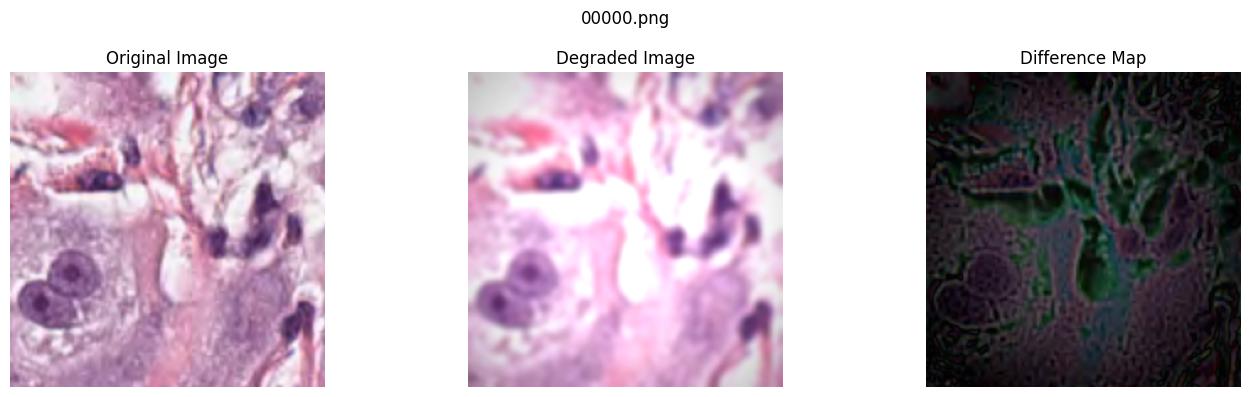

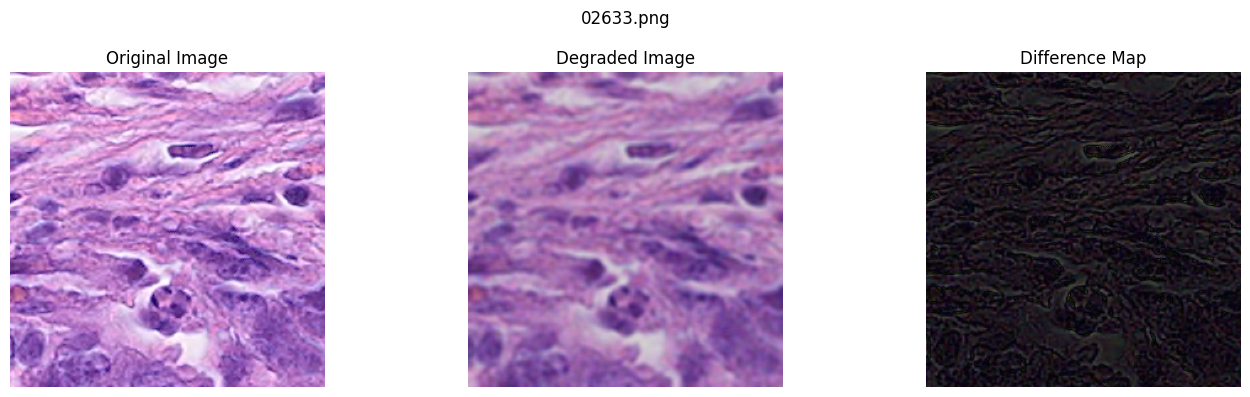

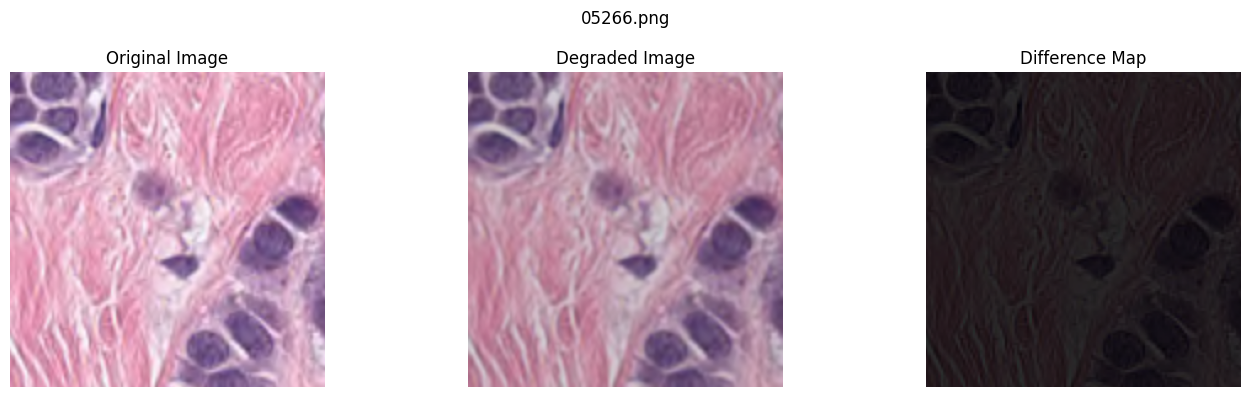

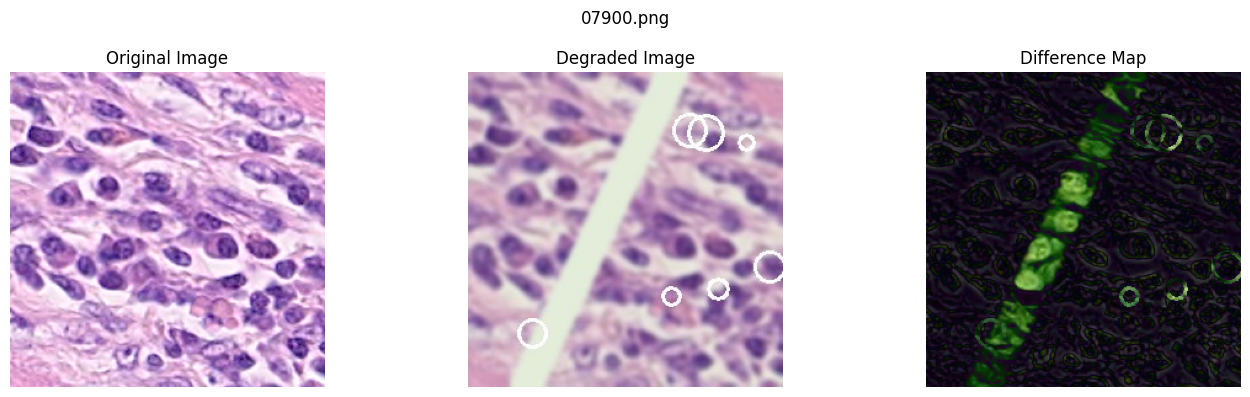

In [ ]:
# ============================================================
# QUICK DEMO — 4 EXISTING IMAGE PAIRS
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = "/content/drive/MyDrive/AI_Readiness_Project/AI_Readiness_Dataset (1)"

ORIGINAL_DIR = os.path.join(ROOT, "original")
DEGRADED_DIR = os.path.join(ROOT, "degraded")
DIFFERENCE_DIR = os.path.join(ROOT, "difference_maps")

# Validate the actual folders
for folder in [ORIGINAL_DIR, DEGRADED_DIR]:
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Folder not found: {folder}")

# Match images by filename
valid_ext = (".png", ".jpg", ".jpeg", ".tif", ".tiff")

original_files = {
    f for f in os.listdir(ORIGINAL_DIR)
    if f.lower().endswith(valid_ext)
}
degraded_files = {
    f for f in os.listdir(DEGRADED_DIR)
    if f.lower().endswith(valid_ext)
}

common_files = sorted(original_files & degraded_files)

if not common_files:
    raise RuntimeError("No matching original/degraded image pairs found.")

# Select up to four evenly spaced examples
n = min(4, len(common_files))
indices = np.linspace(0, len(common_files) - 1, n, dtype=int)
selected_files = [common_files[i] for i in indices]

print(f"Displaying {len(selected_files)} examples.")
print("Read-only preview: no files will be saved or regenerated.")

for filename in selected_files:
    original = np.array(
        Image.open(os.path.join(ORIGINAL_DIR, filename)).convert("RGB")
    )
    degraded = np.array(
        Image.open(os.path.join(DEGRADED_DIR, filename)).convert("RGB")
    )

    # Align image sizes in memory if necessary
    if original.shape != degraded.shape:
        degraded = np.array(
            Image.fromarray(degraded).resize(
                (original.shape[1], original.shape[0])
            )
        )

    diff_path = os.path.join(DIFFERENCE_DIR, filename)

    if os.path.isfile(diff_path):
        difference = np.array(
            Image.open(diff_path).convert("RGB")
        )
    else:
        # Calculate difference temporarily without saving
        difference = np.abs(
            original.astype(np.int16) - degraded.astype(np.int16)
        ).clip(0, 255).astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    for ax, img, title in zip(
        axes,
        [original, degraded, difference],
        ["Original Image", "Degraded Image", "Difference Map"]
    ):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(filename)
    plt.tight_layout()
    plt.show()

Displaying 4 existing image pairs.


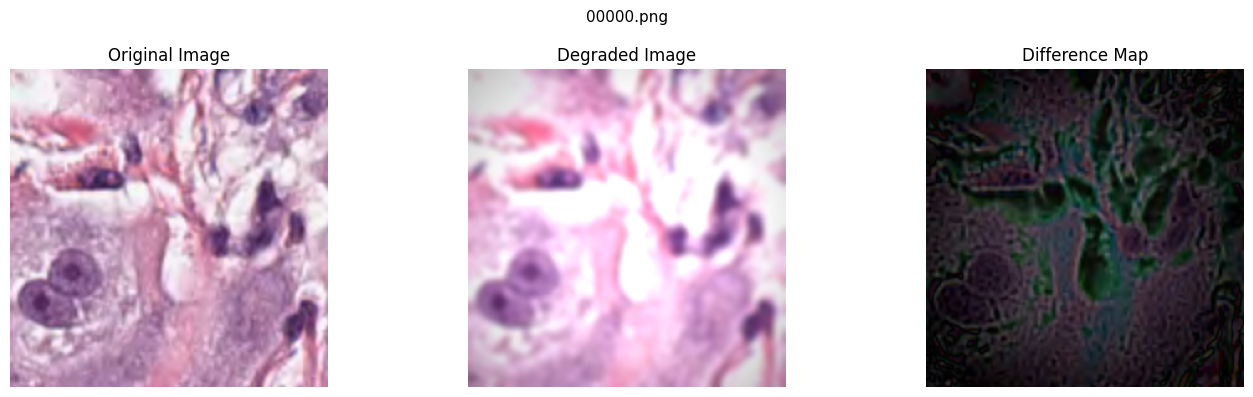

Image: 00000.png
Degradation type(s): brightness,vignette,jpeg,blur,contrast
Severity: Moderate
Severity score: 56.06
Number of degradations: 5
-----------------------------------------------------------------


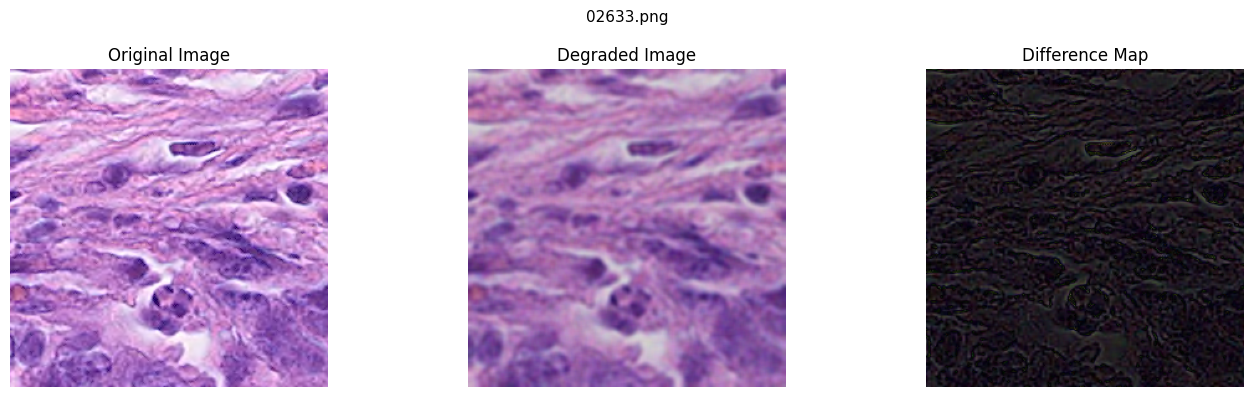

Image: 02633.png
Degradation type(s): gaussian_noise,contrast,blur
Severity: Moderate
Severity score: 46.55
Number of degradations: 3
-----------------------------------------------------------------


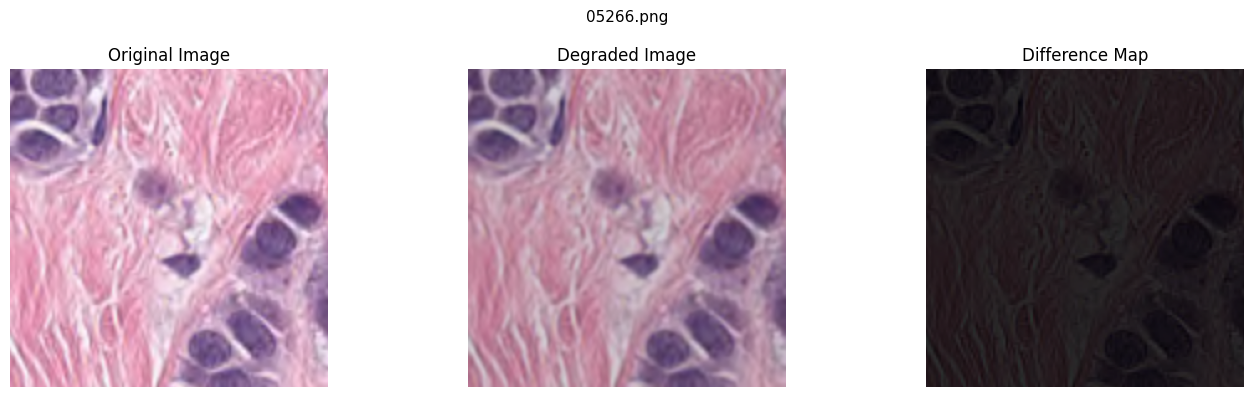

Image: 05266.png
Degradation type(s): brightness,contrast,blur
Severity: Mild
Severity score: 12.91
Number of degradations: 3
-----------------------------------------------------------------


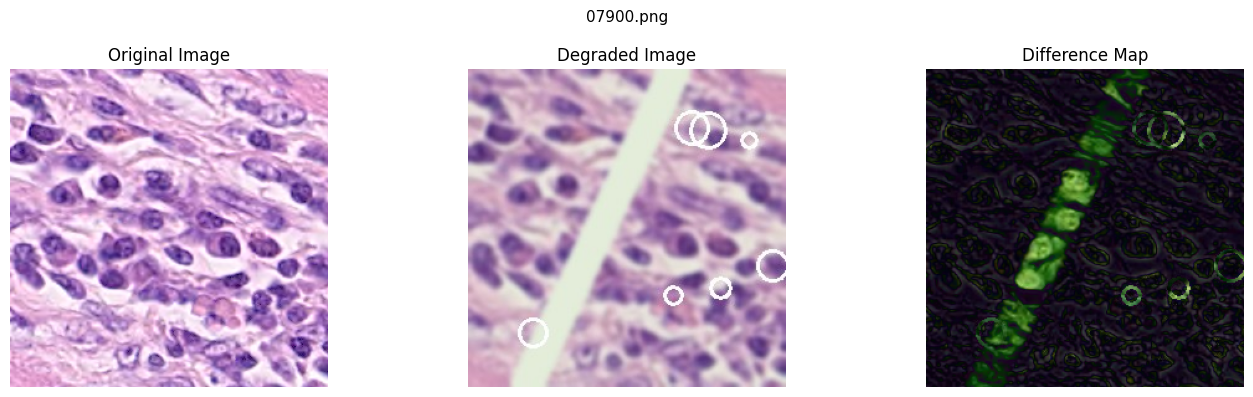

Image: 07900.png
Degradation type(s): tissue_fold,stain_variation,air_bubbles,jpeg
Severity: Mild
Severity score: 32.4
Number of degradations: 4
-----------------------------------------------------------------


In [ ]:
# ============================================================
# DEMO: ORIGINAL vs DEGRADED + DEGRADATION TYPE AND SEVERITY
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

ROOT = "/content/drive/MyDrive/AI_Readiness_Project/AI_Readiness_Dataset (1)"

ORIGINAL_DIR = os.path.join(ROOT, "original")
DEGRADED_DIR = os.path.join(ROOT, "degraded")
DIFFERENCE_DIR = os.path.join(ROOT, "difference_maps")
CSV_PATH = os.path.join(ROOT, "metadata.csv")

# Load metadata when available
metadata = None
if os.path.isfile(CSV_PATH):
    metadata = pd.read_csv(CSV_PATH)
    if "image_name" in metadata.columns:
        metadata["image_name"] = metadata["image_name"].astype(str)
        metadata = metadata.drop_duplicates("image_name").set_index("image_name")
    else:
        metadata = None
        print("Metadata CSV has no image_name column; showing image pairs only.")
else:
    print("metadata.csv not found. Image pairs will still be displayed.")

# Check folders
for folder in [ORIGINAL_DIR, DEGRADED_DIR]:
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Folder not found: {folder}")

valid_ext = (".png", ".jpg", ".jpeg", ".tif", ".tiff")

original_files = {
    f for f in os.listdir(ORIGINAL_DIR)
    if f.lower().endswith(valid_ext)
}
degraded_files = {
    f for f in os.listdir(DEGRADED_DIR)
    if f.lower().endswith(valid_ext)
}

common_files = sorted(original_files & degraded_files)

if not common_files:
    raise RuntimeError("No matching original/degraded image pairs found.")

# Choose up to four examples
n = min(4, len(common_files))
indices = np.linspace(0, len(common_files) - 1, n, dtype=int)
selected_files = [common_files[i] for i in indices]

print(f"Displaying {len(selected_files)} existing image pairs.")

for filename in selected_files:
    original = np.array(
        Image.open(os.path.join(ORIGINAL_DIR, filename)).convert("RGB")
    )
    degraded = np.array(
        Image.open(os.path.join(DEGRADED_DIR, filename)).convert("RGB")
    )

    # Align dimensions in memory if needed
    if original.shape != degraded.shape:
        degraded = np.array(
            Image.fromarray(degraded).resize(
                (original.shape[1], original.shape[0])
            )
        )

    # Difference map: use existing file or calculate temporarily
    diff_path = os.path.join(DIFFERENCE_DIR, filename)
    if os.path.isfile(diff_path):
        difference = np.array(
            Image.open(diff_path).convert("RGB")
        )
    else:
        difference = np.abs(
            original.astype(np.int16) - degraded.astype(np.int16)
        ).clip(0, 255).astype(np.uint8)

    # Retrieve metadata for this image
    row = None
    if metadata is not None and filename in metadata.index:
        row = metadata.loc[filename]

    def get_value(columns, default="Not available"):
        if row is None:
            return default
        for col in columns:
            if col in row.index and pd.notna(row[col]):
                return row[col]
        return default

    degradation_type = get_value(
        ["degradations", "degradation_type", "degradation_types"]
    )
    severity = get_value(["severity", "severity_level"])
    severity_score = get_value(["severity_score", "overall_score"])
    num_degradations = get_value(["num_degradations"])

    # Plot images
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    for ax, img, title in zip(
        axes,
        [original, degraded, difference],
        ["Original Image", "Degraded Image", "Difference Map"]
    ):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(filename, fontsize=11)
    plt.tight_layout()
    plt.show()

    # Show actual metadata values below the images
    print(f"Image: {filename}")
    print(f"Degradation type(s): {degradation_type}")
    print(f"Severity: {severity}")
    print(f"Severity score: {severity_score}")
    print(f"Number of degradations: {num_degradations}")
    print("-" * 65)